# Joint bias in $A_B$ and $F$ from neglecting hyperillumination

This is the analysis of `AB_Bias.ipynb`, extended to heat redistribution. The noiseless "data" (Asimov dataset) are a `hyperillum` phase curve with Bond albedo $A_{B,\rm true}$ and no heat redistribution. They are fitted with `naive_redist`, the point-source model with Kreidberg & Loeb (2016) heat redistribution, with $A_B$, $F$ and the baseline free. The truth has $F = 0$, so the fitted $F$ is itself the bias in $F$. For comparison, the $A_B$-only fit of `AB_Bias` (`naive`, which equals `naive_redist` at $F = 0$) is shown alongside.

In [1]:
import numpy as np
import os
import contextlib, io
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

# Exoplanet Archive aggregate (not used here since the bias maps moved to Bias_Maps.ipynb)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Target, as in AB_Bias.ipynb
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, r1, r2, R, T2_eff, a_AU = planet.args

u, u_B = DEFAULT_U, DEFAULT_U_B   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)

In [3]:
# Albedos (baseline settings, HItargets_utils.py)
A_B = DEFAULT_A_B                         # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

In [4]:
# Filter to be used
instrument =  "MIRI/LRS" # "JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1280W"
filter_path = filter_loc(instrument)
lambda_range = filter_lambda(instrument)

In [5]:
# Instrument Parameters
n_bins = DEFAULT_N_BINS # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes]
sigma_1min = rms_1min(planet, instrument)
n_orbits = DEFAULT_N_ORBITS # number of orbits observed

PandExo inputs for TOI-2431 b  [instrument=MIRI/LRS (PandExo: MIRI LRS)]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.534        R_earth          <- pl_rade
    rs_rsun    = 0.651        R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.7475       h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Group Numbe

In [6]:
# Plot style and colours (F: blue ramp, hyperillumination: orange, A_B-only fit: grey, target: green star) come from simple_bias_analysis
set_plot_style()
F_small = np.array([0., 0.005, 0.01, 0.015, 0.02])   # heat redistributions compared with the truth in 1.

## Detectability and parameter bias analysis

The noise per minute comes from PandExo for the chosen instrument and target (printed below).

In [7]:
l1, l2 = lambda_range

A_B_true = A_B  # injected Bond albedo of the hyperillumination truth
F_true = 0.     # the hyperillumination truth has no heat redistribution, so a fitted F IS its bias

# context for the bias-analysis functions imported from simple_bias_analysis.py (fit ranges A_B_BOUNDS, F_BOUNDS by default)
cfg = FittingConfig(planet=planet, filter_path=filter_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_B=u_B, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")


Noise Level (1min) = 62.9 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin = 8.1 ppm


### 1. Pure Detectability

These plots compare `hyperillum` with `naive_redist` at the true $A_B$ for small redistributions, $F$ = 0 to 0.02. At $F = 0$, `naive_redist` is the naive curve of `AB_Bias`.

In [8]:
# Full phase curves (reflected + thermal) at the true A_B: hyperillumination, and naive_redist for each F in F_small
curve_kw = dict(u=u, u_B=u_B, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

def curves(model, F):
    t_, pc, _ = full_PhaseCurve(planet, lambda_range, insolation_model=model, F=F, **curve_kw)
    _, lc, _ = full_PhaseCurve(planet, lambda_range, insolation_model=model, F=F, include_transit=False, **curve_kw)   # transit removed: phase modulation + occultation only
    return t_, pc, lc

runs = [("hyperillum", None)] + [("naive_redist", F) for F in F_small]
out = Parallel(n_jobs=-1, backend="loky")(delayed(curves)(m, F) for m, F in runs)
get_reusable_executor().shutdown(wait=True)   # free the memory SPIDERMAN leaks in the workers
t_k, pc_k, lc_k = out[0]
redist_curves = dict(zip(F_small, out[1:]))   # F -> (t, phase curve, light curve)

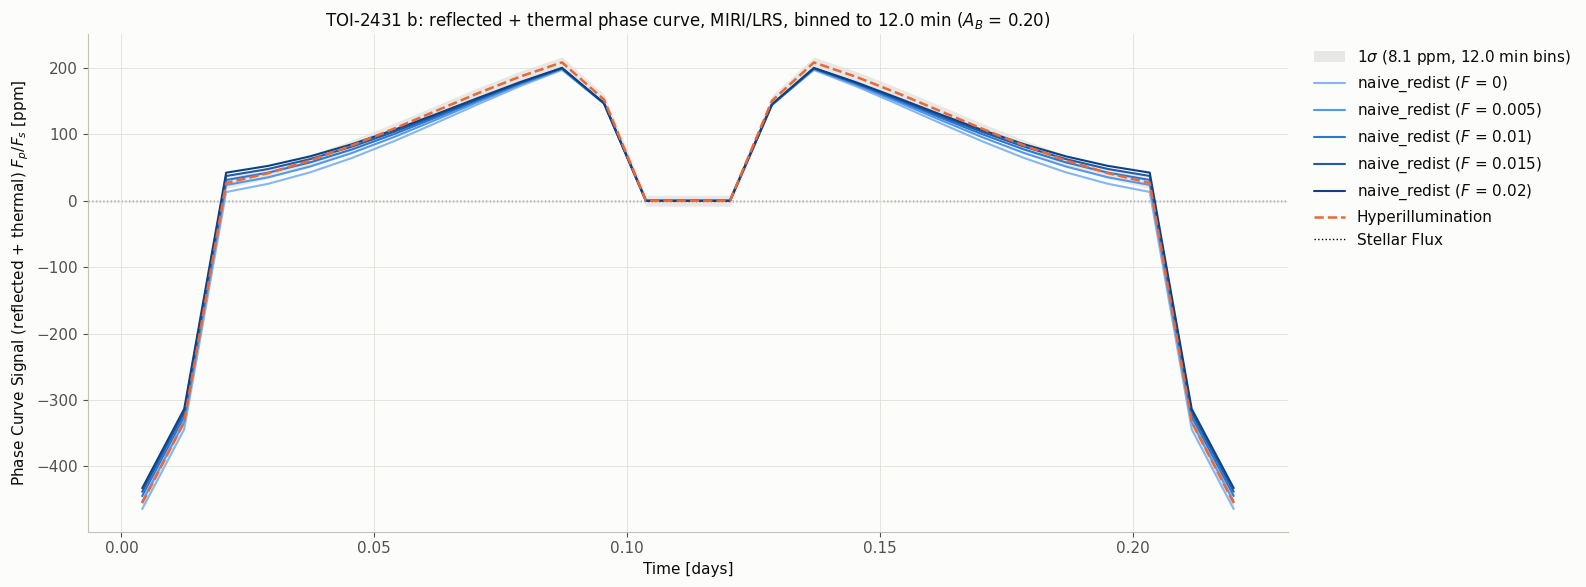

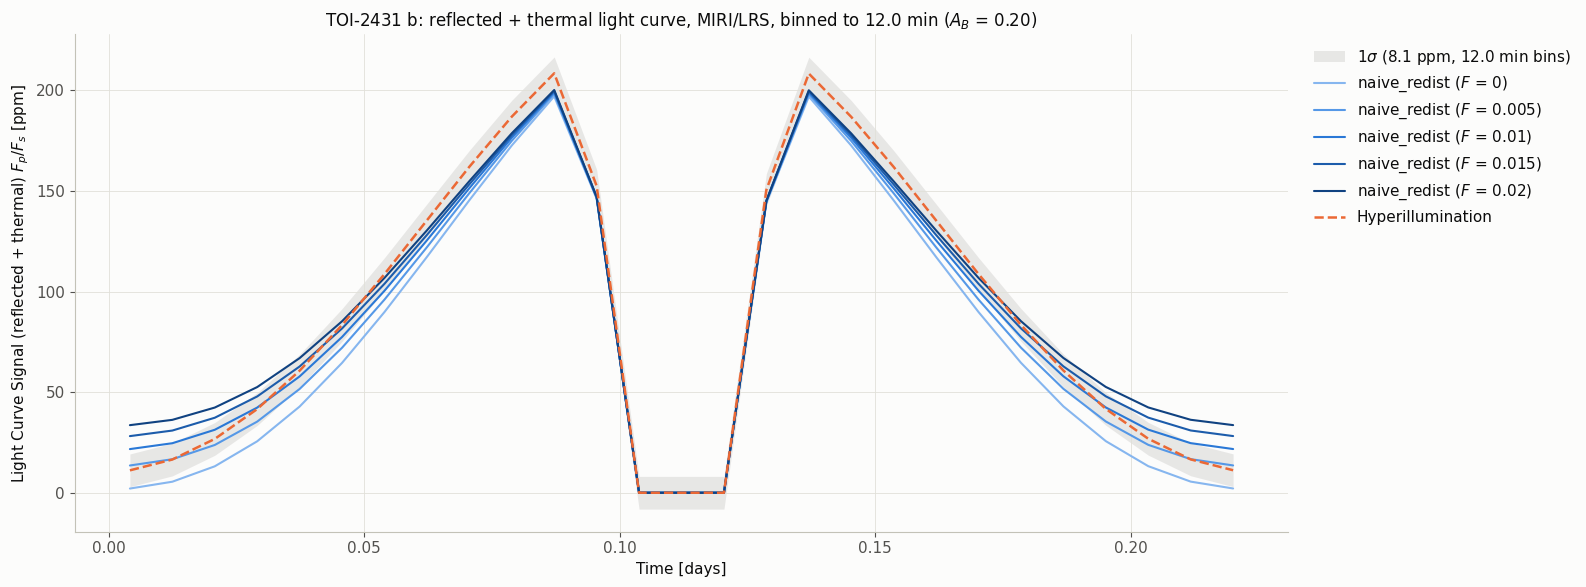

In [9]:
PAPER_MODE = False
# signal [ppm] of each curve for the two views: the phase curve with the transit, and the light curve without it
views = [("phase curve", r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]", lambda pc, lc: (pc - 1) * 1e6),
         ("light curve", r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]", lambda pc, lc: lc * 1e6)]

for name, ylabel, signal in views:
    tb_k, yb_k = bin_curve(t_k, signal(pc_k, lc_k), minutes_binning)

    plt.figure(figsize=(16, 6))
    plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color=INK_2, alpha=0.12, lw=0, label=rf"$1\sigma$ ({sigma_bin:.1f} ppm, {minutes_binning:.1f} min bins)")
    for F, col in zip(F_small, F_COLORS):
        t_F, pc_F, lc_F = redist_curves[F]
        plt.plot(*bin_curve(t_F, signal(pc_F, lc_F), minutes_binning), lw=1.5, color=col, label=f"naive_redist ($F$ = {F:g})")
    plt.plot(tb_k, yb_k, lw=1.8, ls="--", color=C_HI, label="Hyperillumination", zorder=5)
    if name == "phase curve": stellar_flux_line()   # only the view with the transit

    plt.xlabel("Time [days]")
    plt.ylabel(ylabel)
    plt.title(f"{planet.name}: reflected + thermal {name}, {instrument}, binned to {minutes_binning:.1f} min ($A_B$ = {A_B:.2f})")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.))
    plt.tight_layout()
    paper_figure(f"fabbias_{name.replace(' ', '')}_binned_{planet.name.replace(' ', '')}", PAPER_MODE)
    plt.show()

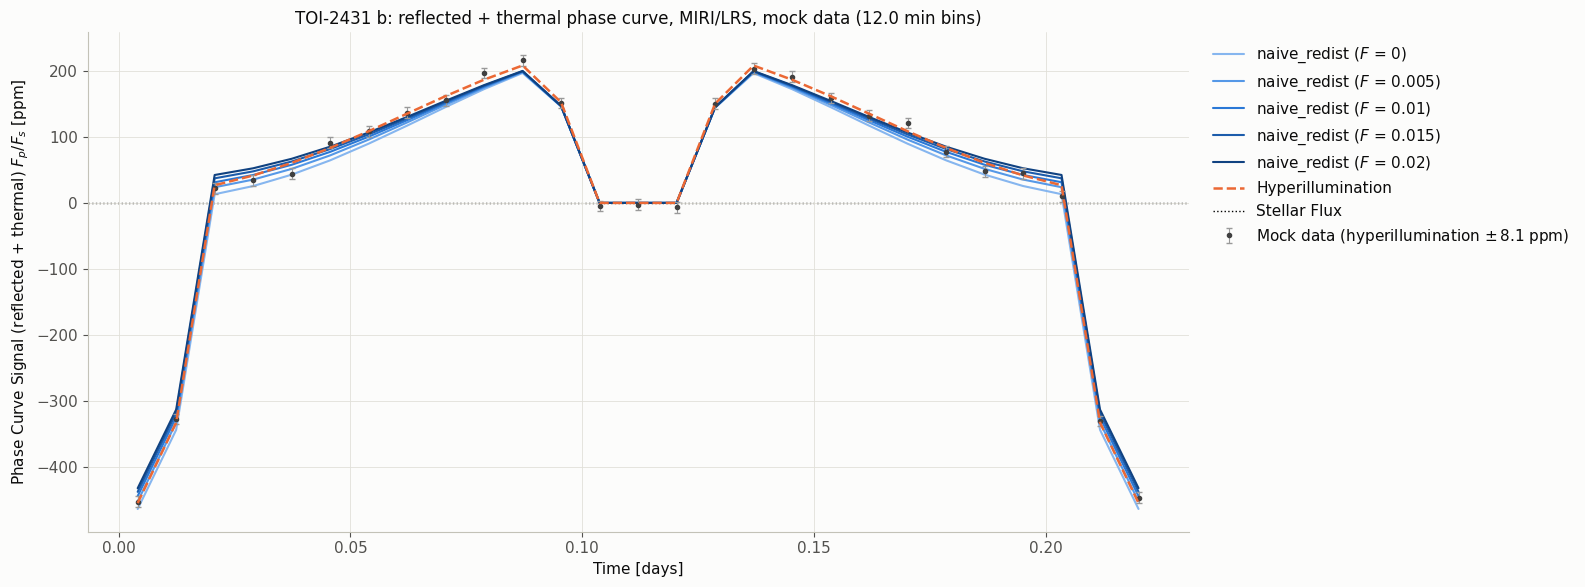

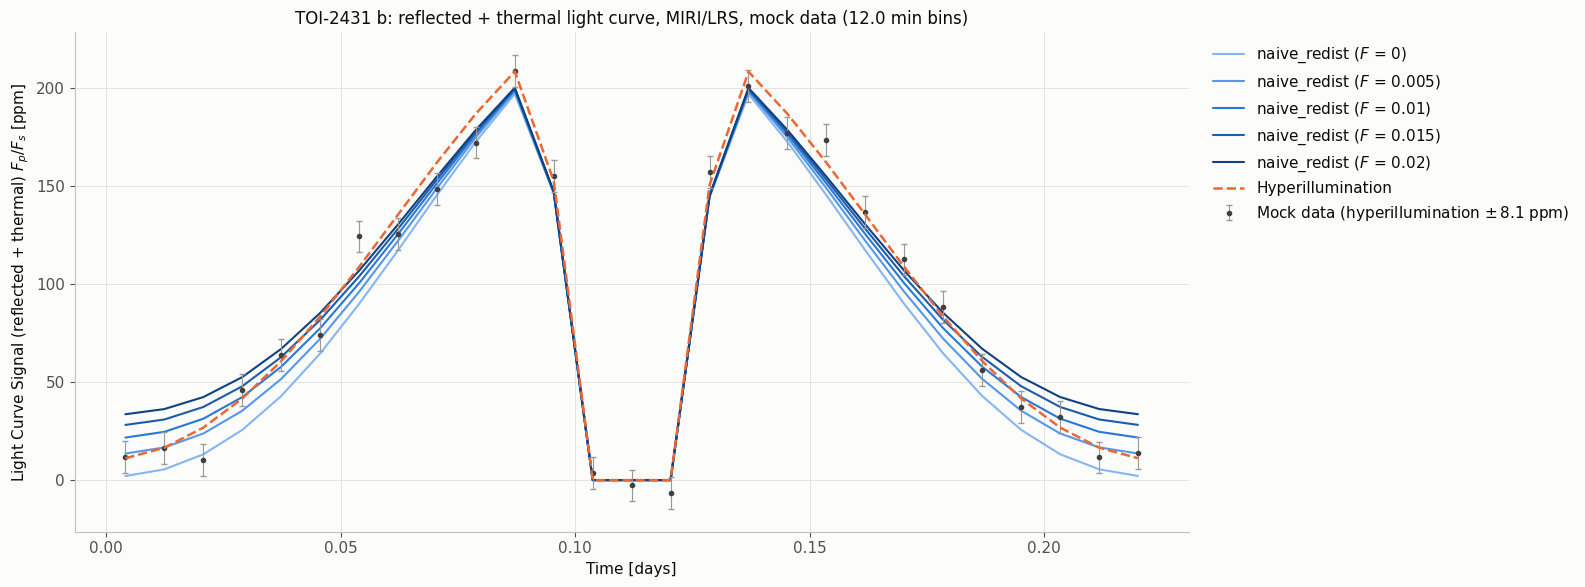

In [10]:
PAPER_MODE = False
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

for name, ylabel, signal in views:
    tb_k, yb_k = bin_curve(t_k, signal(pc_k, lc_k), minutes_binning)   # hyperillumination model, binned [ppm]
    y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)          # mock data ~ N(hyperillum, sigma_bin)

    plt.figure(figsize=(16, 6))
    plt.errorbar(tb_k, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.1f}$ ppm)", **MOCK_KW)
    for F, col in zip(F_small, F_COLORS):
        t_F, pc_F, lc_F = redist_curves[F]
        plt.plot(*bin_curve(t_F, signal(pc_F, lc_F), minutes_binning), lw=1.5, color=col, label=f"naive_redist ($F$ = {F:g})")
    plt.plot(tb_k, yb_k, lw=1.8, ls="--", color=C_HI, label="Hyperillumination", zorder=6)
    if name == "phase curve": stellar_flux_line()   # only the view with the transit
    plt.xlabel("Time [days]")
    plt.ylabel(ylabel)
    plt.title(f"{planet.name}: reflected + thermal {name}, {instrument}, mock data ({minutes_binning:.1f} min bins)")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.))
    plt.tight_layout()
    paper_figure(f"fabbias_{name.replace(' ', '')}_mock_{planet.name.replace(' ', '')}", PAPER_MODE)
    plt.show()

### 2. Bias in recovered $A_B$ and $F$ when hyperillumination is neglected - 2-Parameter Fit

In [11]:
# demo: fit naive (A_B only, as in AB_Bias) and naive_redist (A_B and F) to the hyperillumination truth and report the recovered biases
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

# sqrt(chi2) is S_perp, the truth-to-manifold distance in sigma_bin units — NOT a sigma under any standard test.
# Fitted-vs-fitted discrimination: E[Lambda] = S_perp^2, sd = 2*S_perp, so the significance is S_perp/2. As goodness of fit: S_perp^2/sqrt(2*(n_bins-2)). Neither is the significance printed. bias/sigma is the criterion; this line is a distance.
for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    A_fit2, F_fit2, chi2_2, rms_2 = fit_redist(cfg, truth, free_offset=free_offset)
    T_night = float(surface_temperature(np.pi, planet, "naive_redist", A_B=A_fit2, F=F_fit2))   # nightside temperature the joint fit implies (the truth's antistellar point is at 0 K)
    print(f"free_offset={free_offset}   ({cfg.n_orbits} orbits, {cfg.n_bins} bins)")
    print(f"   A_B only : A_B {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} ({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  "
          f"chi2={chi2:.3f}  resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma")
    print(f"   A_B and F: A_B {A_B_true:.3f} -> {A_fit2:.3f}  bias={A_fit2-A_B_true:+.3f} ({100*(A_fit2-A_B_true)/A_B_true:+.1f}%)  "
          f"chi2={chi2_2:.3f}  resid_rms={rms_2:.2f} ppm  significance={np.sqrt(chi2_2):.2f} sigma")
    print(f"              F {F_true:g} -> {F_fit2:.4f} (bias={F_fit2-F_true:+.4f}, implied nightside T = {T_night:.0f} K)   "
          f"chi2 improvement from freeing F: {chi2 - chi2_2:.3f}\n")

free_offset=True   (5 orbits, 27 bins)
   A_B only : A_B 0.200 -> 0.140  bias=-0.060 (-29.8%)  chi2=12.609  resid_rms=5.56 ppm  significance=3.55 sigma
   A_B and F: A_B 0.200 -> 0.031  bias=-0.169 (-84.5%)  chi2=4.617  resid_rms=3.36 ppm  significance=2.15 sigma
              F 0 -> 0.0058 (bias=+0.0058, implied nightside T = 656 K)   chi2 improvement from freeing F: 7.991

free_offset=False   (5 orbits, 27 bins)
   A_B only : A_B 0.200 -> 0.000  bias=-0.200 (-100.0%)  chi2=34.491  resid_rms=9.20 ppm  significance=5.87 sigma
   A_B and F: A_B 0.200 -> 0.037  bias=-0.163 (-81.7%)  chi2=4.627  resid_rms=3.37 ppm  significance=2.15 sigma
              F 0 -> 0.0056 (bias=+0.0056, implied nightside T = 650 K)   chi2 improvement from freeing F: 29.865



free offset="False" is not really meaningful, since the normalization has an error.

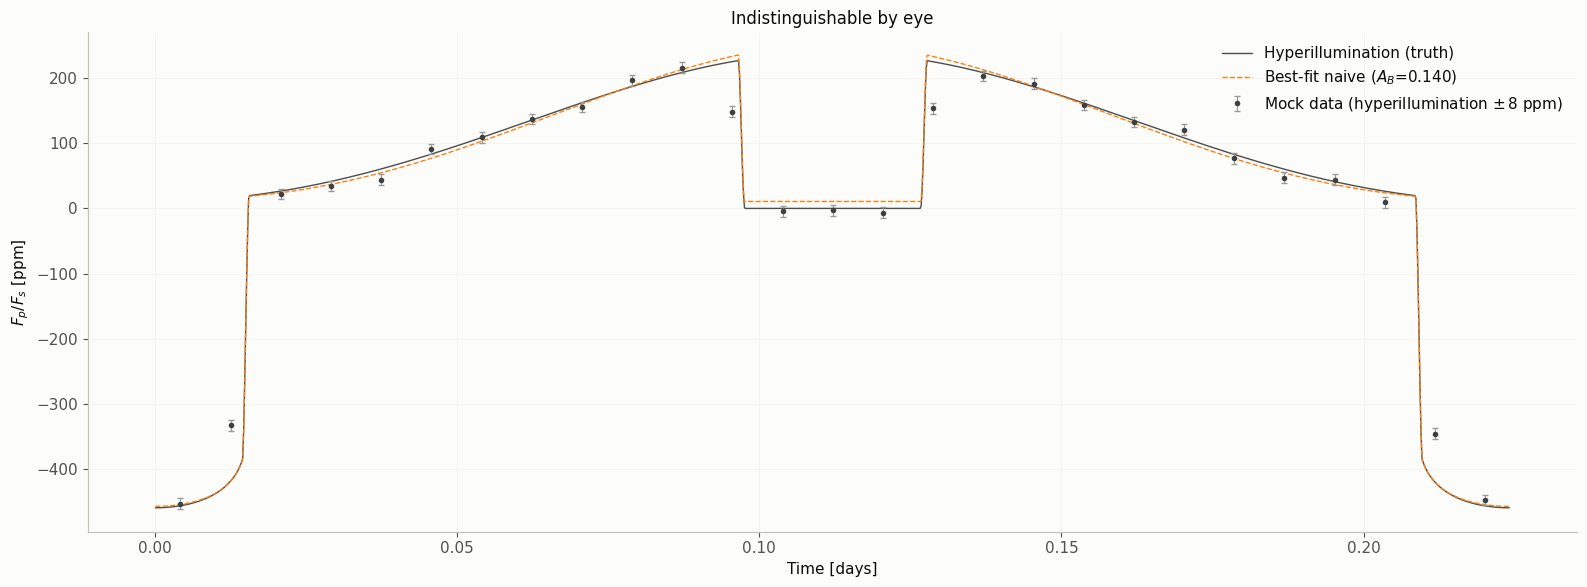

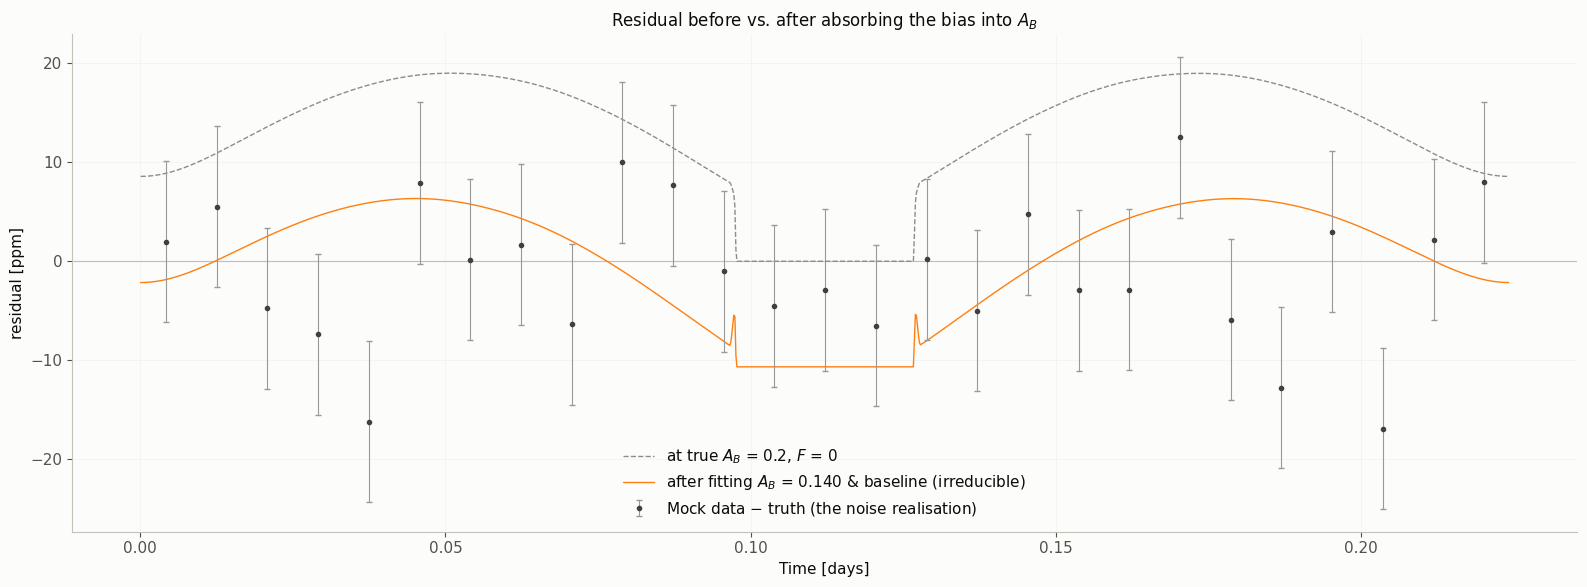

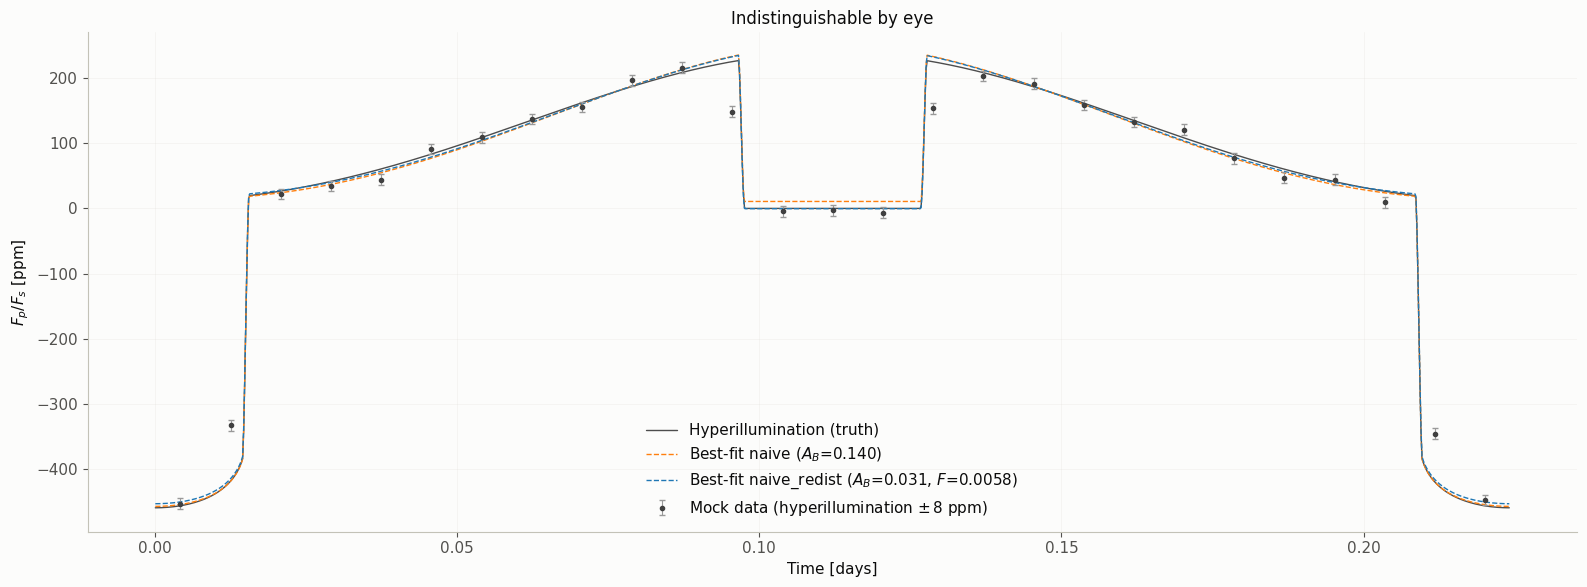

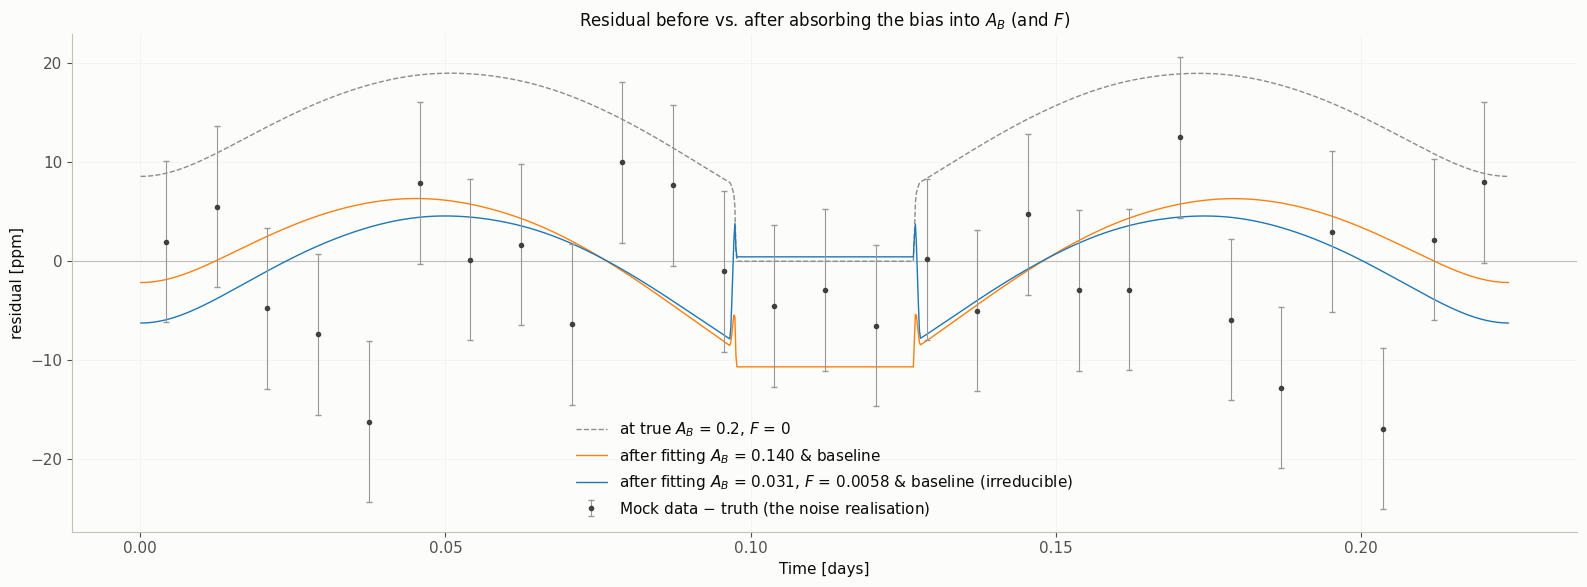

In [12]:
PAPER_MODE = False
# before vs after absorbing the bias into A_B (naive) or into A_B and F (naive_redist)
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
A_fit2, F_fit2, _, _ = fit_redist(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]   # at the true values: A_B_true, F = 0
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()
redist_f  = model_pcurve(cfg, "naive_redist", A_fit2, F=F_fit2)[1]
redist_f  = redist_f + (truth - redist_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(43).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.

# Same two figures as AB_Bias.ipynb section 2 (same colours), drawn twice: first without, then with the joint A_B + F fit.
C_TRUTH, C_TRUE_RESID, C_FIT, C_JOINT = "0.3", "0.55", "C1", "C0"   # truth (dark grey), residual at the true values (grey, dashed), A_B-only fit (orange), joint fit (blue)
for with_joint in (False, True):
    # Figure 1: truth vs best fit(s)
    fig, ax = plt.subplots(figsize=(16, 6))
    ax.errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **MOCK_KW)
    ax.plot(t_, truth,   lw=1, color=C_TRUTH, label="Hyperillumination (truth)")
    ax.plot(t_, naive_f, lw=1, ls="--", color=C_FIT, label=f"Best-fit naive ($A_B$={A_fit:.3f})")
    if with_joint:
        ax.plot(t_, redist_f, lw=1, ls="--", color=C_JOINT, label=f"Best-fit naive_redist ($A_B$={A_fit2:.3f}, $F$={F_fit2:.4f})")
    ax.set_ylabel(r"$F_p/F_s$ [ppm]"); ax.set_xlabel("Time [days]")
    ax.set_title("Indistinguishable by eye")
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    paper_figure(f"fabbias_fit_vs_truth{'_joint' if with_joint else ''}_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
    plt.show()

    # Figure 2: residuals on one axes, with the same mock data as the noise the bias has to beat
    fig, ax = plt.subplots(figsize=(16, 6))
    ax.axhline(0., color="0.7", lw=.8, zorder=1)
    ax.errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **MOCK_KW)
    ax.plot(t_, truth - naive_0, lw=1, ls="--", color=C_TRUE_RESID, label=rf"at true $A_B$ = {A_B_true:.1f}, $F$ = 0")
    ax.plot(t_, truth - naive_f, lw=1, color=C_FIT, label=rf"after fitting $A_B$ = {A_fit:.3f} & baseline" + ("" if with_joint else " (irreducible)"))
    if with_joint:
        ax.plot(t_, truth - redist_f, lw=1, color=C_JOINT, label=rf"after fitting $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f} & baseline (irreducible)")
    ax.set_ylabel("residual [ppm]"); ax.set_xlabel("Time [days]")
    ax.set_title(r"Residual before vs. after absorbing the bias into $A_B$" + (" (and $F$)" if with_joint else ""))
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    paper_figure(f"fabbias_residuals{'_joint' if with_joint else ''}_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
    plt.show()

The $\chi^2$ landscape of the joint fit is shown below. It uses the same noiseless residual as `fit_redist` (baseline free) on an $(A_B, F)$ grid. The contours mark $\Delta\chi^2 = 2.30$ and $6.18$ above the minimum: models inside them could not be told apart from the best fit at 68 % and 95 % with this observation.

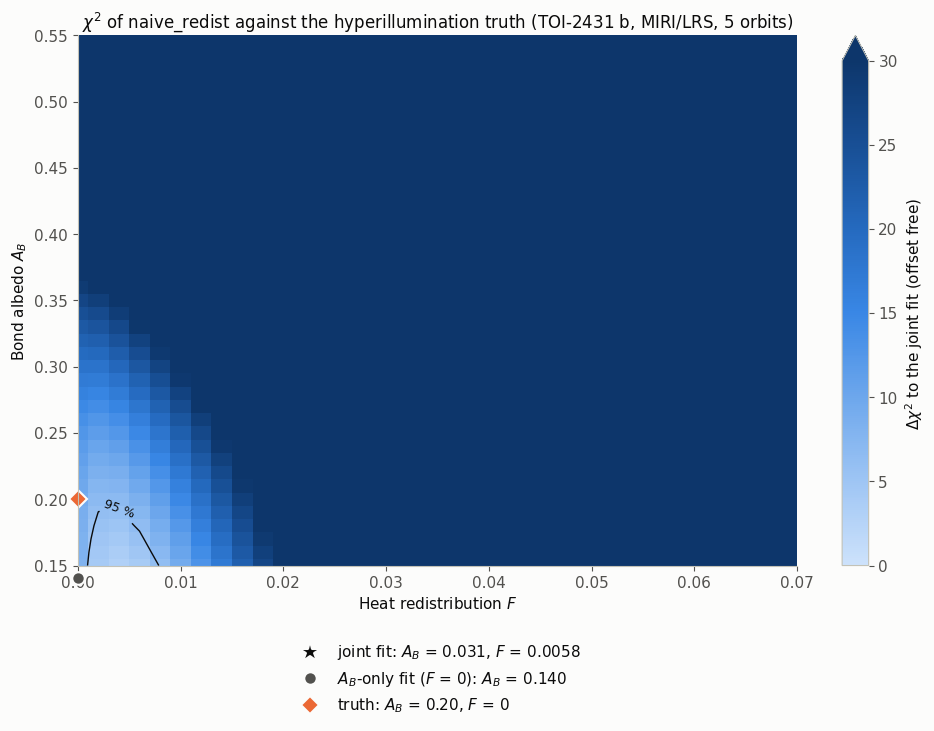

ValueError: zero-size array to reduction operation minimum which has no identity

In [13]:
PAPER_MODE = False
F_MAX = 0.07   # plotted F range: widen it if the 95 % contour does not close inside the plot
AB_grid = np.linspace(0.15, 0.55, 41)
F_grid = np.linspace(0., F_MAX, 36)
d_chi2 = chi2_landscape(cfg, truth, AB_grid, F_grid) - fit_chi2(cfg, truth, "naive_redist", A_fit2, F=F_fit2)   # relative to the joint best fit
# d_chi2 is referenced to the joint fit, not to the grid minimum, and plot_chi2_landscape has vmin=0 — an underconverged fit would be invisible. print(d_chi2.min()) must be >= 0.

fig, ax = plot_chi2_landscape(F_grid, AB_grid, d_chi2, F_MAX)
ax.plot(F_fit2, A_fit2, "*", ms=16, color=INK, mec="#fcfcfb", mew=1.5, label=f"joint fit: $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f}")
ax.plot(0., A_fit, "o", ms=9, color=C_NAIVE, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"$A_B$-only fit ($F$ = 0): $A_B$ = {A_fit:.3f}")
ax.plot(F_true, A_B_true, "D", ms=9, color=C_HI, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"truth: $A_B$ = {A_B_true:.2f}, $F$ = 0")
ax.set_title(f"$\\chi^2$ of naive_redist against the hyperillumination truth ({planet.name}, {instrument}, {cfg.n_orbits} orbits)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
paper_figure(f"fabbias_chi2_landscape_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

(A_lo, A_hi), F_hi = chi2_region(d_chi2, AB_grid, F_grid)
print(f"68 % region on the grid: A_B in [{A_lo:.2f}, {A_hi:.2f}],  F <= {F_hi:.3f}")

### 3. Bias vs. true Bond albedo $A_B$

In [ ]:
PAPER_MODE = False
# Vary the TRUE Bond albedo and refit both models at each value (single target geometry, free baseline; free_offset=False is not meaningful here -- see 2.).
# Bias = fit - truth; the truth has F = 0, so the fitted F is the bias in F. Fisher sigmas (baseline marginalised) turn the biases into a measurability.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))
# No rail check here (unlike bias_cell), so the low true A_B points where a fit sits at the A_B = 0 floor (listed in the output) enter the curves with a one-sided derivative — that is the kink at the left edge of both panels. Mask them.
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=True)
bias_naive, sig_naive = sweep["naive"]["bias_A_B"], sweep["naive"]["sigma_A_B"]
bias_joint, F_joint, sig_joint, sig_F = (sweep["naive_redist"][k] for k in ("bias_A_B", "F_fit", "sigma_A_B", "sigma_F"))
bs_naive, _ = measurability(bias_naive, sig_naive, cfg.sigma_1min)             # systematic in units of the statistical error bar, at the CURRENT sigma_1min
bs_joint, crit_joint = measurability(bias_joint, sig_joint, cfg.sigma_1min)
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

# Freeing F widens A_B's MARGINAL sigma as well as enlarging its bias, so the two effects partly cancel -- which is why the ratio, not the bias alone, is the decision number.
target_label = f"{planet.name} ($A_B$={A_B_true:.2f})"
fig, _ = plot_joint_bias_vs_true_AB(A_B_grid, sweep, i0, target_label=target_label,
                                    title=f"Bias in recovered $A_B$ and $F$ from neglecting hyperillumination, vs. the true $A_B$ ({planet.name}, {instrument})")
paper_figure(f"fabbias_vs_true_AB_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
# Measurability: |Delta A_B| / sigma_A_B (left) and the spurious F / sigma_F (right); the right axes give the per-minute precision at which each bias is a 1-sigma effect.
fig, _ = plot_joint_measurability(A_B_grid, sweep, i0, cfg, target_label=target_label,
                                  title=f"Measurability of the biases ({planet.name}, {instrument})")
paper_figure(f"fabbias_measurability_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

railed = {name: A_B_grid + b < 1e-3 for name, b in (("A_B only", bias_naive), ("joint", bias_joint))}   # fits sitting at the A_B = 0 floor
ok = ~railed["joint"] & ~railed["A_B only"]
print(f"at {planet.name}: A_B-only bias {bias_naive[i0]:+.3f},  joint bias {bias_joint[i0]:+.3f} with F = {F_joint[i0]:.4f}")
for name, r in railed.items():
    print(f"{name:8s} fit rails at A_B = 0 for true A_B <= {A_B_grid[r].max():.2f}" if r.any() else f"{name:8s} fit never rails at A_B = 0")
print(f"elsewhere: F from {F_joint[ok].min():.4f} to {F_joint[ok].max():.4f},  joint / A_B-only bias from {np.min(bias_joint[ok] / bias_naive[ok]):.1f} to {np.max(bias_joint[ok] / bias_naive[ok]):.1f}")

fac = cfg.sigma_1min / crit_joint[i0]   # = 1 / bias_sigma; how much finer the photometry must get before the bias is a 1-sigma effect
print(f"\n|bias|/sigma_A_B at {planet.name}: {bs_naive[i0]:.2f} (A_B only), {bs_joint[i0]:.2f} (joint)"
      f"   ->  sigma_1min_crit = {crit_joint[i0]:.1f} ppm/min vs {cfg.sigma_1min:.1f} delivered"
      f"  ({fac:.1f}x finer, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits})")
print(f"spurious redistribution: F = {F_joint[i0]:.4f} +- {sig_F[i0]:.4f}  ->  {F_joint[i0] / sig_F[i0]:.2f} sigma   (F_true = 0, so this is the false-atmosphere significance)")

At the target, freeing $F$ enlarges the albedo bias; the output prints both biases and the fitted $F$. For example: $-0.142$ instead of $-0.051$ with $F = 0.006$ (MIRI/LRS, TOI-2431 b, $A_B = 0.3$, $u_B = 0.6$, 5 orbits), and $-0.078$ instead of $-0.032$ with $F = 0.020$ (NIRSpec G395H NRS1, TOI-2431 b, $A_B = 0.3$, $u_B = 0.6$, 5 orbits).
Across the grid, the output gives the range of the joint / $A_B$-only bias ratio and of $F$. So far the enlargement has held for every unrailed $A_B$, with a nearly constant ratio: 2.5–2.8 (MIRI/LRS, TOI-2431 b, $u_B = 0.6$, 5 orbits) and 2.4–2.7 (NIRSpec G395H NRS1, TOI-2431 b, $u_B = 0.6$, 5 orbits). An earlier MIRI/LRS result that the ratio drops to 1 where the joint fit returns $F = 0$ was an optimizer artefact: the former Nelder-Mead fit got stuck on the $F = 0$ bound.

At low true $A_B$ the fits can rail at the physical floor $A_{B,\rm fit}=0$; their absolute bias then saturates at $-A_B$ and their relative bias at $-100\%$. The output lists the railed points of each fit. So far $A_B$ has been underestimated and $F$ overestimated throughout.